In [ ]:
# image handeling
from PIL import Image, ImageFilter
from scipy import ndimage

# import libraries
import numpy as np
import matplotlib.pyplot as plt

Size (width, height): (1600, 1600)
Mode: RGB
Array shape (height, width, channels): (1600, 1600, 3)


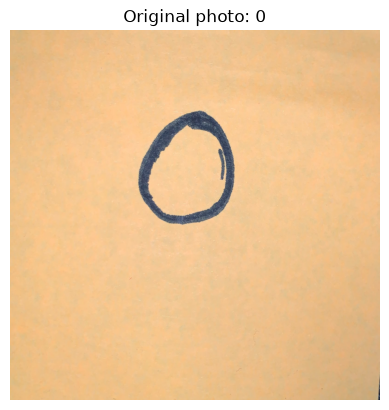

In [20]:
# Read the photo of digit 0
img = Image.open("data/raw/0.jpeg")

# Basic facts about the image
print("Size (width, height):", img.size)
print("Mode:", img.mode)
print("Array shape (height, width, channels):", np.array(img).shape)

# Display the original photo
plt.imshow(img)
plt.title("Original photo: 0")
plt.axis("off")
plt.show()

Shape: (1600, 1600)
Data type: uint8
Darkest pixel: 6
Brightest pixel: 240
Typical background (median): 194.0


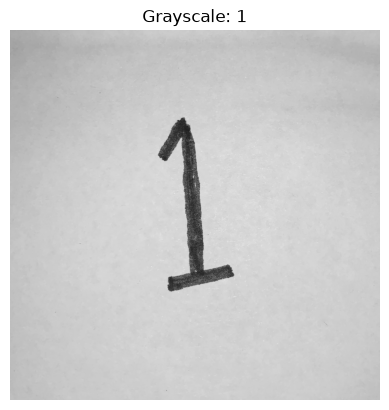

In [21]:
# Read the photo and convert to grayscale ("L" = one channel, brightness only)
img = Image.open("data/raw/1.jpeg").convert("L")
gray_image = np.array(img)

print("Shape:", gray_image.shape)
print("Data type:", gray_image.dtype)
print("Darkest pixel:", gray_image.min())
print("Brightest pixel:", gray_image.max())
print("Typical background (median):", np.median(gray_image))

plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale: 1")
plt.axis("off")
plt.show()

### Preprocess handwritten image

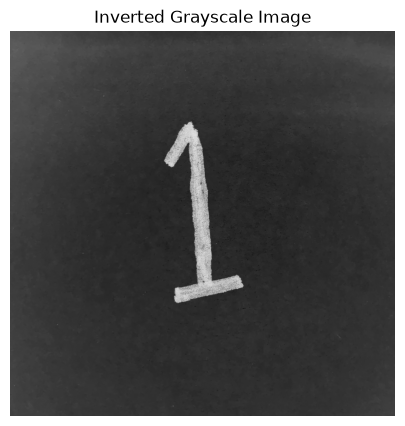

In [22]:
# Invert the grayscale image
inverted_image = 255 - gray_image

# Display the inverted image
plt.figure(figsize=(5, 5))
plt.imshow(inverted_image, cmap="gray")
plt.title("Inverted Grayscale Image")
plt.axis("off")
plt.show()

### Thresholding and Cropping the Digit

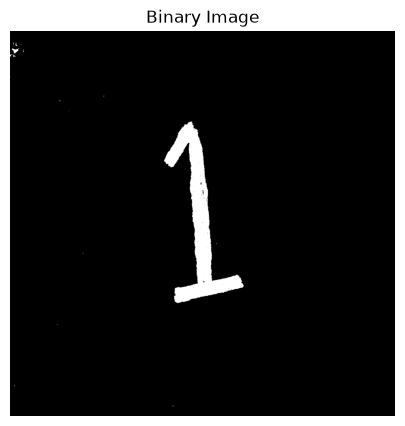

In [23]:
# Apply binary thresholding
threshold = 100
binary_image = np.where(inverted_image > threshold, 255, 0).astype(np.uint8)

# Display the binary image
plt.figure(figsize=(5, 5))
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

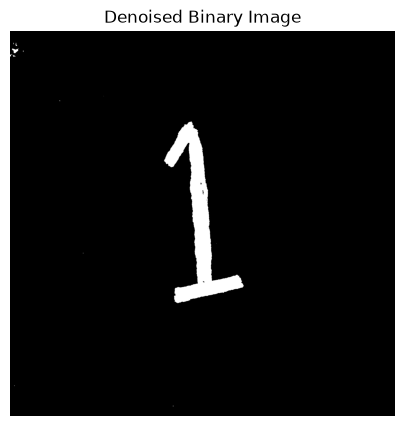

In [24]:
# remove background noise

# Remove small isolated noise using a 3x3 median filter
denoised_image = np.array(
    Image.fromarray(binary_image).filter(ImageFilter.MedianFilter(size=3))
)

# Display the denoised image
plt.figure(figsize=(5, 5))
plt.imshow(denoised_image, cmap="gray")
plt.title("Denoised Binary Image")
plt.axis("off")
plt.show()

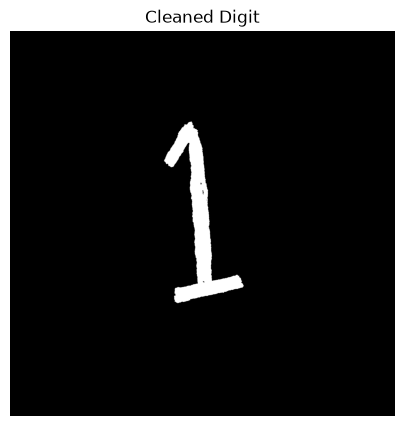

Number of components: 15


In [25]:
# Remove remaining noise using connected components

# Label connected white-pixel regions
labeled_image, number_of_components = ndimage.label(denoised_image > 0)

# Calculate the size of each component
component_sizes = np.bincount(labeled_image.ravel())

# Ignore the background (label 0)
component_sizes[0] = 0

# Find the largest connected component
largest_component = np.argmax(component_sizes)

# Keep only the largest component
cleaned_image = np.where(
    labeled_image == largest_component, 255, 0
).astype(np.uint8)

# Display the cleaned image
plt.figure(figsize=(5, 5))
plt.imshow(cleaned_image, cmap="gray")
plt.title("Cleaned Digit")
plt.axis("off")
plt.show()

print("Number of components:", number_of_components)

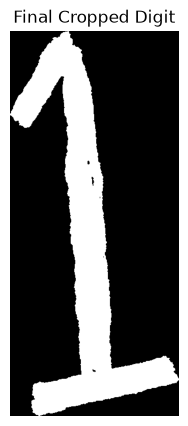

Cropped digit shape: (755, 331)


In [26]:
# crop the cleaned digit

# Find the boundaries of the cleaned digit
rows, cols = np.where(cleaned_image > 0)

top = rows.min()
bottom = rows.max() + 1
left = cols.min()
right = cols.max() + 1

# Crop the digit
cropped_digit = cleaned_image[top:bottom, left:right]

# Display the final cropped digit
plt.figure(figsize=(5, 5))
plt.imshow(cropped_digit, cmap="gray")
plt.title("Final Cropped Digit")
plt.axis("off")
plt.show()

print("Cropped digit shape:", cropped_digit.shape)

### Resize and center the digit

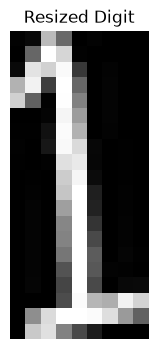

Original cropped shape: (755, 331)
Resized digit shape: (20, 9)


In [27]:
# Resize the Cropped Digit

# Get the original cropped digit dimensions
height, width = cropped_digit.shape

# Calculate the scaling factor
scale = 20 / max(height, width)

# Calculate new dimensions while preserving aspect ratio
new_height = round(height * scale)
new_width = round(width * scale)

# Resize the cropped digit
resized_digit = np.array(
    Image.fromarray(cropped_digit).resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )
)

# Display the resized digit
plt.figure(figsize=(4, 4))
plt.imshow(resized_digit, cmap="gray")
plt.title("Resized Digit")
plt.axis("off")
plt.show()

print("Original cropped shape:", cropped_digit.shape)
print("Resized digit shape:", resized_digit.shape)

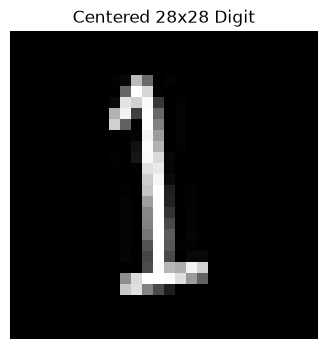

Final image shape: (28, 28)


In [ ]:
# Place the Digit on a 28 × 28 Canvas

# Create a black 28x28 canvas
canvas = np.zeros((28, 28), dtype=np.uint8)

# Calculate the position to center the resized digit
y_offset = (28 - new_height) // 2
x_offset = (28 - new_width) // 2

# Place the resized digit onto the canvas
canvas[
    y_offset:y_offset + new_height,
    x_offset:x_offset + new_width
] = resized_digit

# Display the centered digit
plt.figure(figsize=(4, 4))
plt.imshow(canvas, cmap="gray")
plt.title("Centered 28x28 Digit")
plt.axis("off")
plt.show()

print("Final image shape:", canvas.shape)

### Normalize the image

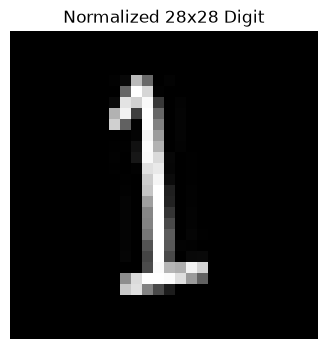

Image shape: (28, 28)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [29]:
# Convert pixel values to the range 0-1
normalized_image = canvas.astype("float32") / 255.0

# Display the normalized image
plt.figure(figsize=(4, 4))
plt.imshow(normalized_image, cmap="gray")
plt.title("Normalized 28x28 Digit")
plt.axis("off")
plt.show()

print("Image shape:", normalized_image.shape)
print("Data type:", normalized_image.dtype)
print("Minimum pixel value:", normalized_image.min())
print("Maximum pixel value:", normalized_image.max())

### Prepare the Image for CNN Input

In [30]:
# Load the trained CNN model
from tensorflow.keras.models import load_model
model = load_model("../../models_saved/model.h5")

# Display the model's expected input shape
print("Model input shape:", model.input_shape)

Model input shape: (None, 28, 28, 1)


In [ ]:
# Add batch and channel dimensions
model_input = normalized_image.reshape(1, 28, 28, 1)

# Verify the prepared input
print("Model input shape:", model_input.shape)
print("Data type:", model_input.dtype)
print("Minimum pixel value:", model_input.min())
print("Maximum pixel value:", model_input.max())

Model input shape: (1, 28, 28, 1)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


### Predict Handwritten digit 1

In [34]:
# Predict the image loaded from data/raw/1.jpeg
single_image_predictions = model.predict(model_input)

predicted_digit = np.argmax(single_image_predictions[0])
confidence = single_image_predictions[0][predicted_digit] * 100

print("Actual digit: 1")
print("Predicted digit:", predicted_digit)
print(f"Prediction confidence: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
Actual digit: 1
Predicted digit: 1
Prediction confidence: 98.74%


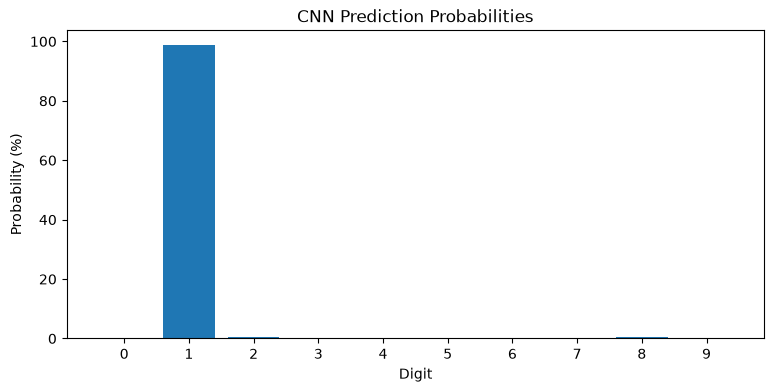

In [36]:
# Display probability scores for all digit classes
plt.figure(figsize=(9, 4))
plt.bar(range(10), single_image_predictions[0] * 100)

plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Probability (%)")
plt.title("CNN Prediction Probabilities")
plt.show()

### Create a reuseable preprocessing function

In [38]:

def preprocess_digit(image_path, threshold=150):

    # 1. Load the image and convert it to grayscale
    gray_image = np.array(
        Image.open(image_path).convert("L")
    )

    # 2. Invert the image (dark digit becomes white)
    inverted_image = 255 - gray_image

    # 3. Apply binary thresholding
    binary_image = np.where(
        inverted_image > threshold, 255, 0
    ).astype(np.uint8)

    # 4. Remove small isolated noise
    denoised_image = np.array(
        Image.fromarray(binary_image).filter(
            ImageFilter.MedianFilter(size=3)
        )
    )

    # 5. Identify connected components
    labeled_image, number_of_components = ndimage.label(
        denoised_image > 0
    )

    if number_of_components == 0:
        raise ValueError(f"No digit detected in {image_path}")

    component_sizes = np.bincount(labeled_image.ravel())
    component_sizes[0] = 0

    # Keep the largest connected component
    largest_component = np.argmax(component_sizes)

    cleaned_image = np.where(
        labeled_image == largest_component, 255, 0
    ).astype(np.uint8)

    # 6. Find the digit boundaries
    rows, cols = np.where(cleaned_image > 0)

    if len(rows) == 0:
        raise ValueError(f"No digit detected in {image_path}")

    top, bottom = rows.min(), rows.max() + 1
    left, right = cols.min(), cols.max() + 1

    # 7. Crop the digit
    cropped_digit = cleaned_image[top:bottom, left:right]

    # 8. Resize while preserving aspect ratio
    height, width = cropped_digit.shape
    scale = 20 / max(height, width)

    new_height = max(1, round(height * scale))
    new_width = max(1, round(width * scale))

    resized_digit = np.array(
        Image.fromarray(cropped_digit).resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )
    )

    # 9. Place the digit at the center of a black 28x28 canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)

    y_offset = (28 - new_height) // 2
    x_offset = (28 - new_width) // 2

    canvas[
        y_offset:y_offset + new_height,
        x_offset:x_offset + new_width
    ] = resized_digit

    # 10. Normalize pixel values
    normalized_image = canvas.astype(np.float32) / 255.0

    return normalized_image


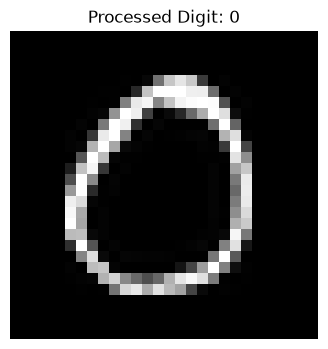

Image shape: (28, 28)
Data type: float32


In [39]:
# Test the function

# Process the handwritten zero
processed_digit = preprocess_digit("data/raw/0.jpeg")

# Display the processed image
plt.figure(figsize=(4, 4))
plt.imshow(processed_digit, cmap="gray")
plt.title("Processed Digit: 0")
plt.axis("off")
plt.show()

print("Image shape:", processed_digit.shape)
print("Data type:", processed_digit.dtype)

### Process and visualize all ten images

In [40]:
# Process all ten handwritten digit images

processed_images = []

for digit in range(10):
    image_path = f"data/raw/{digit}.jpeg"

    # Use threshold 150 for preprocessing
    processed_image = preprocess_digit(image_path, threshold=150)

    processed_images.append(processed_image)

# Convert the list into a NumPy array
processed_images = np.array(processed_images)

print("Processed images shape:", processed_images.shape)
print("Data type:", processed_images.dtype)

Processed images shape: (10, 28, 28)
Data type: float32


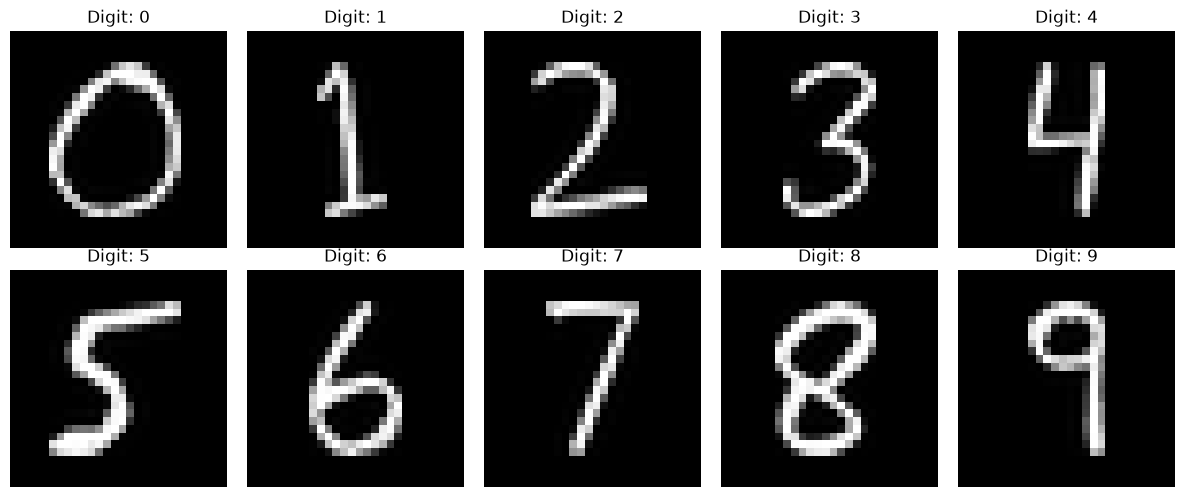

In [41]:
# Display all ten processed digits

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(processed_images[i], cmap="gray")
    plt.title(f"Digit: {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [42]:
# Predict all ten handwritten digits

model_inputs = processed_images.reshape(10, 28, 28, 1)

predictions = model.predict(model_inputs)

predicted_digits = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1) * 100

# Display prediction results
print("MNIST Handwritten Digit Recognition Results\n")

for actual, predicted, confidence in zip(
    range(10), predicted_digits, confidence_scores
):
    print(
        f"Actual: {actual} | "
        f"Predicted: {predicted} | "
        f"Confidence: {confidence:.2f}%"
    )


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
MNIST Handwritten Digit Recognition Results

Actual: 0 | Predicted: 0 | Confidence: 99.51%
Actual: 1 | Predicted: 1 | Confidence: 98.11%
Actual: 2 | Predicted: 2 | Confidence: 99.07%
Actual: 3 | Predicted: 3 | Confidence: 100.00%
Actual: 4 | Predicted: 4 | Confidence: 100.00%
Actual: 5 | Predicted: 5 | Confidence: 99.90%
Actual: 6 | Predicted: 6 | Confidence: 99.60%
Actual: 7 | Predicted: 7 | Confidence: 98.70%
Actual: 8 | Predicted: 8 | Confidence: 100.00%
Actual: 9 | Predicted: 9 | Confidence: 68.27%
